<a href="https://colab.research.google.com/github/CRM48/AIML425-A4/blob/main/GaussianToDogsODE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 0 | Avg Loss: 3.48991
Epoch 500 | Avg Loss: 0.57809
Epoch 1000 | Avg Loss: 0.47727
Epoch 1500 | Avg Loss: 0.46719
Epoch 2000 | Avg Loss: 0.46595
Epoch 2500 | Avg Loss: 0.45688
Epoch 3000 | Avg Loss: 0.45827
Epoch 3500 | Avg Loss: 0.45915
Epoch 4000 | Avg Loss: 0.45898
Epoch 4500 | Avg Loss: 0.45608


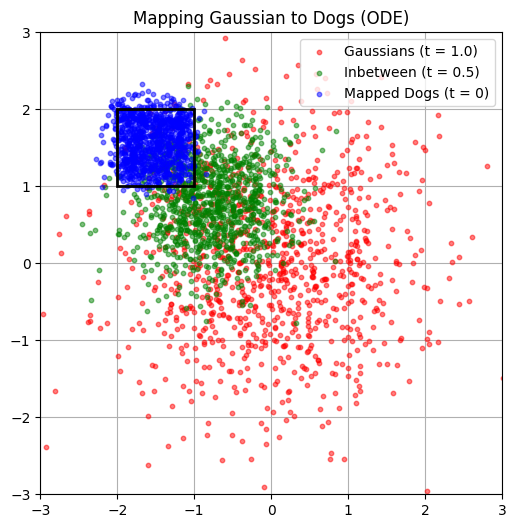

In [4]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Input data

def sample_dogs(n=1000):
    np_samples = np.random.uniform(low=[-2, 1], high=[-1, 2], size=(n, 2))
    return torch.tensor(np_samples, dtype=torch.float32)

def sample_gaussians(n=1000, s=1.0):
    np_samples = np.random.normal(loc=0.0, scale=np.sqrt(s), size=(n, 2))
    return torch.tensor(np_samples, dtype=torch.float32)

# Model

class FlowNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2+1, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x, t):
        xt = torch.cat([x, t], dim=1)
        return self.net(xt)



# Training

model = FlowNet()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

batch_size = 128
n_epochs = 5000

loss_history = []
window = 500

for epoch in range(n_epochs):
    x0 = sample_dogs(batch_size)
    x1 = sample_gaussians(batch_size, s=1.0)

    t = torch.rand(batch_size, 1)

    x_t = (1-t) * x0 + t * x1

    target_v = (x1 - x0)
    pred_v = model(x_t, t)

    loss = ((pred_v - target_v)**2).mean()
    loss_history.append(loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        if len(loss_history) < window:
            avg_loss = sum(loss_history)/len(loss_history)
        else:
            avg_loss = sum(loss_history[-window:])/window
        print(f"Epoch {epoch} | Avg Loss: {avg_loss:.5f}")

# Generate Dogs from Gaussian
x_start = sample_gaussians(1000, s=1.0)
x = x_start.clone()

num_steps = 100
dt = 1.0 / num_steps

# Using Forward Euler:
for i in range(num_steps):
    t_i = torch.full((x.shape[0], 1), 1.0 - i*dt)
    v = model(x, t_i)
    x = x - v * dt  # Euler
    if(i == num_steps/2):
      x_middle = x.detach().cpu()

x_end = x.detach().cpu()

# Plot inputs and outputs
plt.figure(figsize=(6,6))
plt.scatter(x_start[:,0].cpu(), x_start[:,1].cpu(), alpha=0.5, color='red', s=10, label='Gaussians (t = 1.0)')
plt.scatter(x_middle[:,0].cpu(), x_middle[:,1].cpu(), alpha=0.5, color='green', s=10, label='Inbetween (t = 0.5)')
plt.scatter(x_end[:,0], x_end[:,1], alpha=0.5, color='blue', s=10, label='Mapped Dogs (t = 0)')

rect = patches.Rectangle((-2, 1), 1, 1, linewidth=2, edgecolor='black', facecolor='none')
plt.gca().add_patch(rect)

plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.gca().set_aspect('equal')
plt.legend(loc='upper right')
plt.title("Mapping Gaussian to Dogs (ODE)")
plt.grid(True)
plt.gca().set_axisbelow(True)
plt.show()


